# UTS Graf Sains Data

| | |
|---|---|
| Mata kuliah | Graf Sains Data |
| Semester | Gasal 2026/2027 · Ujian Tengah Semester |
| Materi | Python Driver untuk Neo4j dan Rekomendasi |
| Nama | Akmal Rizal |
| NIM | 23031554078 |
| Kelas | 2023A |

Notebook ini menjawab naskah soal secara berurutan. Setiap butir berisi penjelasan, kode, output, dan interpretasi.

| Bagian | Isi |
|---|---|
| 0 | Setup: koneksi Neo4j, fungsi bantu |
| 1 | Tugas Pendahuluan: 1.1 lingkungan · 1.2 driver Neo4j + checkpoint · 1.3 impor RetailRocket |
| 2.1 | Wrangling & EDA: periode, filter, komposisi subgraph, VSM user & item, proyeksi, similarity, sebelum/sesudah |
| 2.2 | Analytics: user acak, rekomendasi KNN (k = 5), Hit@5 & NDCG@5, validasi |
| 3 | Kesimpulan dan ringkasan jawaban |

**Alur data:** `events.csv` → filter periode P1/P2 → `data/events_filtered.csv` → fungsi impor → graf Neo4j (`Visitor`–`Item`) → VSM & proyeksi → relasi `SIMILAR` → rekomendasi KNN → evaluasi terhadap P2.



## 0. Setup

Kredensial dibaca dari berkas `.env` (`USN`, `PASSWD`, `DBNAME`, opsional `URI`) sehingga tidak tertulis di notebook.

- **P1** (training) = 7 Juni – 18 Juli 2015 dan **P2** (testing) = 19 Juli – 1 Agustus 2015, dalam UTC dengan interval `[awal, akhir)`.
- **K = 5** tetangga untuk KNN (soal 2.2.1b) dan **SEED = 2026** untuk semua proses acak.
- Fungsi `cypher()` menjalankan query lewat `driver.execute_query`.

In [52]:
import math
import os
import sys
import time
from pathlib import Path
from IPython.display import display

import matplotlib.pyplot as plt
import neo4j
import networkx as nx
import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
from dotenv import load_dotenv
from neo4j import GraphDatabase, RoutingControl
from tqdm import tqdm

load_dotenv() 
URI = os.getenv("URI", "neo4j://127.0.0.1:7687")
AUTH = (os.environ["USN"], os.environ["PASSWD"])
DB = os.environ["DBNAME"]

RAW_DIR = Path("ecommerce-dataset")
DATA_DIR = Path("data")
FILTERED_CSV = DATA_DIR / "events_filtered.csv"

P1 = (pd.Timestamp("2015-06-07", tz="UTC"), pd.Timestamp("2015-07-19", tz="UTC"))
P2 = (pd.Timestamp("2015-07-19", tz="UTC"), pd.Timestamp("2015-08-02", tz="UTC"))

K = 5        # jumlah tetangga KNN
SEED = 2026

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

driver = GraphDatabase.driver(URI, auth=AUTH, notifications_min_severity="OFF")
driver.verify_connectivity()
driver.execute_query(f"CREATE DATABASE `{DB}` IF NOT EXISTS WAIT", database_="system")  # sudah dipakai sejak 1.2


def cypher(query, db=DB, **params):
    return driver.execute_query(query, params, database_=db, result_transformer_=neo4j.Result.to_df)


print("Terhubung ke", URI, "| database UTS:", DB)

Terhubung ke neo4j://127.0.0.1:7687 | database UTS: midterm-exam


## 1. Tugas Pendahuluan

### 1.1 Persiapan dan Perkenalan Lingkungan

Perintah dari soal:

```text
uv venv myvenv --python 3.10      # atau: python -m venv myenv
conda deactivate                  # matikan environment lain bila ada
source myvenv/bin/activate        # Windows: myvenv\Scripts\activate
uv pip install -r requirements.txt
```

Proyek ini dikelola uv lewat `pyproject.toml` + `uv.lock`, jadi seluruh dependensi cukup dipasang dengan `uv sync` ke `.venv`.

**Penyesuaian versi driver.** Saya pribadi menggunakan dependency `neo4j==6.4.1` dengan alasan pada `requirements.txt` di soal yang menganjurkan `neo4j==4.2.1` yang dimana pada versi tersebut somehow terdapat error, sehingga saya memutuskan menggunakan versi neo4j terbaru saja.

In [2]:
server = driver.get_server_info()
edition = cypher("CALL dbms.components() YIELD edition RETURN edition", db="system").edition[0]
pd.DataFrame(
    [
        ("Python", sys.version.split()[0]),
        ("neo4j (driver)", neo4j.__version__),
        ("pandas", pd.__version__),
        ("numpy", np.__version__),
        ("scipy", scipy.__version__),
        ("networkx", nx.__version__),
        ("Neo4j server", f"{server.agent} ({edition})"),
        ("Protokol Bolt", ".".join(map(str, server.protocol_version))),
    ],
    columns=["komponen", "versi"],
)

,komponen,versi
0,Python,3.10.21
1,neo4j (driver),6.4.1
2,pandas,2.3.3
3,numpy,2.2.6
4,scipy,1.15.3
5,networkx,3.4.2
6,Neo4j server,Neo4j/2026.09.0 (enterprise)
7,Protokol Bolt,6.1


### 1.2 Mempelajari Penggunaan Driver Neo4j

Kode tutorial dari soal dijalankan apa adanya pada database `neo4j`. Satu-satunya perubahan: variabel pada blok `with` diberi nama `tutorial_driver` agar tidak menimpa `driver` utama notebook. `URI` dan `AUTH` sudah diisi dari `.env` di sel Setup.

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )


def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])


with GraphDatabase.driver(URI, auth=AUTH) as tutorial_driver:
    add_friend(tutorial_driver, "Arthur", "Guinevere")
    add_friend(tutorial_driver, "Arthur", "Lancelot")
    add_friend(tutorial_driver, "Arthur", "Merlin")
    print_friends(tutorial_driver, "Arthur")

Guinevere
Lancelot
Merlin


Fungsi `execute_query` mengeksekusi satu query di dalam transaksi terkelola. Parameter Cypher(`$name`, `$friend_name`) diteruskan sebagai argumen biasa, sementara konfigurasi driver seperti `database_` dan `routing_` ditandai dengan akhiran garis bawah. Penggunaan `RoutingControl.READ` menandakan bahwa query bersifat read-only, sehingga sistem kluster dapat mengarahkannya langsung ke server pembaca.


#### Pertanyaan Pendahuluan (Checkpoint)

**1. Nama database yang digunakan:** `neo4j` dipilih dengan alasan default instance-nya.

In [4]:
cypher("SHOW DEFAULT DATABASE YIELD name RETURN name AS database_default", db="system")

,database_default
0,neo4j


**2. Akses ke database lain dalam satu instance.** Satu instance Neo4j bisa menampung beberapa database. Cara memilih dan mengelolanya:

| Cara | Contoh |
|---|---|
| Parameter driver | `execute_query(..., database_="midterm-exam")`, `driver.session(database="midterm-exam")` |
| Klausa Cypher `USE` | ``USE `midterm-exam` MATCH (n) RETURN count(n)`` |
| Perintah Neo4j Browser / cypher-shell | `:use midterm-exam` |
| Perintah administrasi (DDL, dijalankan di database `system`) | `SHOW DATABASES`, `CREATE DATABASE x IF NOT EXISTS`, `ALTER DATABASE`, `STOP DATABASE`, `START DATABASE`, `DROP DATABASE`, `CREATE ALIAS` |
| Composite database | `CREATE COMPOSITE DATABASE gabungan`, lalu `USE gabungan.konstituen MATCH ...` |

Demo di bawah: daftar database dari `system`, lalu query yang dikirim ke session database `neo4j` tetapi membaca database UTS lewat klausa `USE`. Bila notebook dijalankan dari database kosong, hasilnya 0 karena data UTS baru diimpor di 2.1.2.

In [5]:
display(cypher("SHOW DATABASES YIELD name, currentStatus, default RETURN name, currentStatus, default", db="system"))
cypher(f"USE `{DB}` MATCH (n) RETURN count(n) AS jumlah_node_database_uts", db="neo4j")

,name,currentStatus,default
0,midterm-exam,online,False
1,neo4j,online,True
2,system,online,False


,jumlah_node_database_uts
0,784463


**3. Jenis graf pertemanan.** Graf yang terbentuk adalah *labeled property graph* dengan sifat:

- **berarah**: relasi `KNOWS` selalu punya arah `Arthur → teman`;
- **tidak berbobot** dan **homogen**: satu label simpul (`Person`) dan satu tipe relasi (`KNOWS`), tanpa properti bobot;
- **sederhana**: `MERGE` mencegah simpul atau relasi ganda walaupun kode dijalankan ulang;
- berbentuk **star graph S₃ (out-star)**: Arthur di pusat dengan 3 relasi keluar, yaitu pohon berkedalaman 1 (4 simpul, 3 sisi).

Pertemanan sejatinya simetris, tetapi Neo4j selalu menyimpan arah relasi; arah bisa diabaikan saat query dengan pola `-[:KNOWS]-`. Bukti dengan networkx:

,nilai
berarah (directed),True
jumlah simpul,4
jumlah sisi,3
pohon (arah diabaikan),True
isomorfik dengan star graph S3,True
out-degree Arthur,3


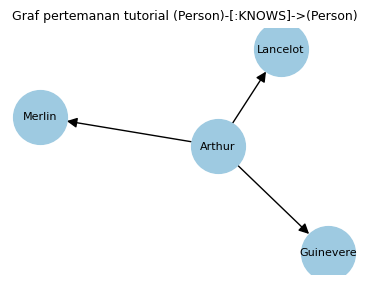

In [6]:
edges = cypher("MATCH (a:Person)-[:KNOWS]->(b:Person) RETURN a.name AS source, b.name AS target", db="neo4j")
G_friend = nx.from_pandas_edgelist(edges, "source", "target", create_using=nx.DiGraph)
display(pd.Series({
    "berarah (directed)": G_friend.is_directed(),
    "jumlah simpul": G_friend.number_of_nodes(),
    "jumlah sisi": G_friend.number_of_edges(),
    "pohon (arah diabaikan)": nx.is_tree(G_friend.to_undirected()),
    "isomorfik dengan star graph S3": nx.is_isomorphic(G_friend.to_undirected(), nx.star_graph(3)),
    "out-degree Arthur": G_friend.out_degree("Arthur"),
}, name="nilai").to_frame())

fig, ax = plt.subplots(figsize=(4.5, 3.2))
nx.draw_networkx(G_friend, nx.spring_layout(G_friend, seed=SEED), ax=ax, node_color="#9ecae1",
                 node_size=1500, font_size=8, arrowsize=15)
ax.set_title("Graf pertemanan tutorial (Person)-[:KNOWS]->(Person)", fontsize=9)
ax.axis("off")
plt.show()

#### CYPHER Total Reset

`MATCH (n) DETACH DELETE n` menghapus semua simpul beserta relasinya di database yang sedang dipakai, sehingga berbahaya pada *shared database*. Karena itu database selalu disebut eksplisit: reset di bawah hanya menyentuh database tutorial `neo4j`, bukan database UTS. Untuk graf besar, penghapusan dipecah per batch (`CALL (n) { DETACH DELETE n } IN TRANSACTIONS`) agar tidak kehabisan memori. Cara ini dipakai opsi `--reset` pada skrip impor di 1.3.

In [7]:
print("sebelum reset:", cypher("MATCH (n) RETURN count(n) AS n", db="neo4j").n[0], "simpul di database neo4j")
cypher("MATCH (n) DETACH DELETE n", db="neo4j")
print("sesudah reset:", cypher("MATCH (n) RETURN count(n) AS n", db="neo4j").n[0], "simpul")

sebelum reset: 4 simpul di database neo4j
sesudah reset: 0 simpul


### 1.3 Impor Data RetailRocket ke Database Neo4j

Sumber data: *RetailRocket recommender system dataset* (Roman Zykov) di Kaggle. Perintah unduh dari soal:

```text
# Windows PowerShell
curl.exe -L -o ecommerce-dataset.zip `
  https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

# Linux / macOS
curl -L -o ecommerce-dataset.zip \
  https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset
```

Arsip diekstrak ke folder `ecommerce-dataset/`.

In [8]:
for f in sorted(RAW_DIR.glob("*.csv")):
    print(f"{f.name:28s} {f.stat().st_size / 1e6:8.1f} MB")
if not (RAW_DIR / "events.csv").exists():
    raise FileNotFoundError("Unduh dataset dengan perintah di atas lalu ekstrak ke folder ecommerce-dataset/")

category_tree.csv                 0.0 MB
events.csv                       94.2 MB
item_properties_part1.csv       484.3 MB
item_properties_part2.csv       408.9 MB


Fitur pada `events.csv`:

| Fitur | Keterangan |
|---|---|
| `timestamp` | waktu event dalam unix epoch **milidetik** |
| `visitorid` | ID unik pengunjung |
| `event` | jenis interaksi: `view`, `addtocart`, `transaction` |
| `itemid` | ID unik produk |
| `transactionid` | ID transaksi, hanya terisi untuk event `transaction` |

In [9]:
raw = pd.read_csv(RAW_DIR / "events.csv", dtype={"transactionid": "Int64"})
raw["datetime"] = pd.to_datetime(raw["timestamp"], unit="ms", utc=True)
raw.info()
raw.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 6 columns):
 #   Column         Dtype              
---  ------         -----              
 0   timestamp      int64              
 1   visitorid      int64              
 2   event          object             
 3   itemid         int64              
 4   transactionid  Int64              
 5   datetime       datetime64[ns, UTC]
dtypes: Int64(1), datetime64[ns, UTC](1), int64(3), object(1)
memory usage: 128.8+ MB


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,<NA>,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,<NA>,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,<NA>,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,<NA>,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,<NA>,2015-06-02 05:02:17.106000+00:00


In [10]:
print("rentang waktu:", raw.datetime.min(), "s/d", raw.datetime.max())
display(pd.DataFrame({"nilai unik": raw.nunique(), "kosong": raw.isna().sum()}))
display(raw.event.value_counts().to_frame("jumlah event"))
pd.crosstab(raw.event, raw.transactionid.notna()).rename(
    columns={False: "transactionid kosong", True: "transactionid terisi"})

rentang waktu: 2015-05-03 03:00:04.384000+00:00 s/d 2015-09-18 02:59:47.788000+00:00


,nilai unik,kosong
timestamp,2750455,0
visitorid,1407580,0
event,3,0
itemid,235061,0
transactionid,17672,2733644
datetime,2750455,0


,jumlah event
event,
view,2664312
addtocart,69332
transaction,22457


transactionid,transactionid kosong,transactionid terisi
event,,
addtocart,69332,0
transaction,0,22457
view,2664312,0


**Interpretasi.** Data berisi 2.756.101 event dari 1.407.580 visitor dan 235.061 item selama 3 Mei – 18 September 2015 (UTC). Jenis event sangat timpang: 96,7% `view`, 2,5% `addtocart`, dan 0,8% `transaction`. `transactionid` hanya terisi pada event `transaction` (22.457 baris, 17.672 ID unik karena satu transaksi bisa berisi beberapa item). Jadi nilai kosongnya bukan data hilang, melainkan memang tidak berlaku. Jumlah `timestamp` unik (2.750.455) lebih kecil dari jumlah baris; sebagian di antaranya adalah baris duplikat persis yang dibuang di 2.1.2.

**Session ke database `system`.** Contoh soal membuka `driver.session(database="system")`. Database `system` adalah tempat perintah administrasi, jadi session ini dipakai untuk membuat database UTS bila belum ada (`CREATE DATABASE ... IF NOT EXISTS`, fitur multi-database Neo4j Enterprise/Desktop) dan menampilkan daftar database.

In [11]:
with driver.session(database="system") as session:
    session.run(f"CREATE DATABASE `{DB}` IF NOT EXISTS WAIT").consume()
    databases = session.run("SHOW DATABASES YIELD name, currentStatus RETURN name, currentStatus").to_df()
databases

,name,currentStatus
0,midterm-exam,online
1,neo4j,online
2,system,online


In [12]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE").consume()
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE").consume()


def reset_database(session):
    # auto-commit transaction: dihapus per 10.000 simpul agar heap tidak penuh
    session.run("MATCH (n) CALL (n) { DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS").consume()


def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp, fold: row.fold}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, fold: row.fold}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, fold: row.fold,
                             transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)


def import_events(csv_path, batch_size=10_000, reset=False):
    with open(csv_path, encoding="utf-8") as f:
        total_rows = sum(1 for _ in f) - 1  # tanpa baris header
    total_chunks = math.ceil(total_rows / batch_size)
    with driver.session(database=DB) as session:
        if reset:
            print(f"Mengosongkan database '{DB}'...")
            reset_database(session)
        create_constraints(session)
        chunks = pd.read_csv(csv_path, chunksize=batch_size, dtype={"transactionid": "string"})
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            chunk["transactionid"] = chunk["transactionid"].fillna("")
            session.execute_write(import_batch, chunk.to_dict(orient="records"))
    print(f"Proses impor berhasil: {total_rows:,} baris.")

## 2. Soal UTS — 2.1 Wrangling dan EDA


### 2.1.1 Penentuan dua periode

Data RetailRocket hanya mencakup 3 Mei – 18 September 2015, jadi contoh periode di soal (2023/2024) tidak bisa dipakai apa adanya. Dipilih dua periode **berurutan tanpa tumpang tindih** — P2 langsung setelah P1 — sebagai *fold* training dan testing:

In [13]:
pd.DataFrame({
    "fold": ["P1", "P2"],
    "peran": ["training", "testing"],
    "awal (UTC, inklusif)": [P1[0], P2[0]],
    "akhir (UTC, eksklusif)": [P1[1], P2[1]],
    "durasi (hari)": [(P1[1] - P1[0]).days, (P2[1] - P2[0]).days],
    "batas timestamp (ms)": [f"[{P1[0].value // 10**6}, {P1[1].value // 10**6})",
                             f"[{P2[0].value // 10**6}, {P2[1].value // 10**6})"],
}).set_index("fold")

,peran,"awal (UTC, inklusif)","akhir (UTC, eksklusif)",durasi (hari),batas timestamp (ms)
fold,,,,,
P1,training,2015-06-07 00:00:00+00:00,2015-07-19 00:00:00+00:00,42,"[1433635200000, 1437264000000)"
P2,testing,2015-07-19 00:00:00+00:00,2015-08-02 00:00:00+00:00,14,"[1437264000000, 1438473600000)"


Alasan pemilihan:

- **Proporsi 6 : 2 minggu (75 : 25).** P1 cukup panjang untuk membangun similarity, sedangkan P2 cukup panjang untuk menangkap kunjungan ulang.
- **Dimulai pada hari minggu.** Kedua periode mulai hari Minggu dan panjangnya kelipatan 7 hari, sehingga setiap hari dalam seminggu terwakili seimbang.
- **Berurutan.** Evaluasi meniru kondisi nyata: model dilatih dengan masa lalu (P1) lalu diuji pada masa sesudahnya (P2).
- **Di tengah rentang data**, jauh dari awal (3 Mei) dan akhir data (18 September) yang tidak lengkap.

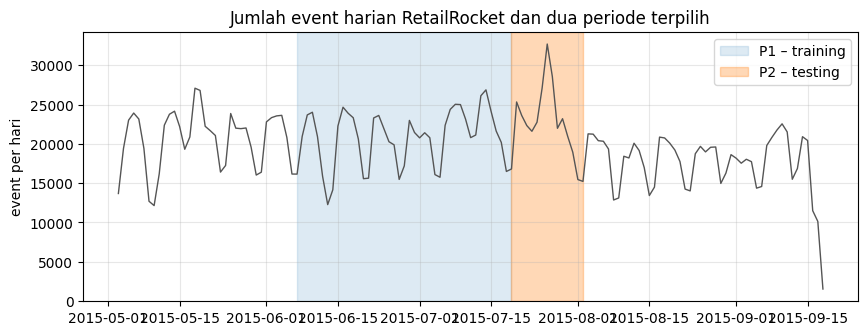

In [14]:
daily = raw.set_index("datetime").resample("D").size()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily.index.tz_convert(None), daily.values, color="#555", lw=1)
ax.axvspan(P1[0].tz_convert(None), P1[1].tz_convert(None), color="tab:blue", alpha=0.15, label="P1 – training")
ax.axvspan(P2[0].tz_convert(None), P2[1].tz_convert(None), color="tab:orange", alpha=0.3, label="P2 – testing")
ax.set(title="Jumlah event harian RetailRocket dan dua periode terpilih", ylabel="event per hari")
ax.legend()
plt.show()

### 2.1.2 Filter timestamp dan penyimpanan CSV

Langkah persiapan data:

1. buang baris duplikat persis (`timestamp`, `visitorid`, `event`, `itemid` sama);
2. pilih baris yang waktunya berada di P1 ∪ P2, memakai kolom `datetime` hasil konversi `timestamp` (epoch ms) ke UTC dengan interval `[awal, akhir)`;
3. tambahkan kolom `fold` (`P1`/`P2`);
4. simpan ke `data/events_filtered.csv`, dengan `transactionid` tetap bilangan bulat (bukan `4000.0`).

In [15]:
dedup = raw.drop_duplicates(["timestamp", "visitorid", "event", "itemid"])
in_p1 = (dedup.datetime >= P1[0]) & (dedup.datetime < P1[1])
in_p2 = (dedup.datetime >= P2[0]) & (dedup.datetime < P2[1])

events = dedup[in_p1 | in_p2].copy()
events["fold"] = np.where(in_p1[in_p1 | in_p2], "P1", "P2")
events = events.sort_values("timestamp", kind="stable")

DATA_DIR.mkdir(exist_ok=True)
events[["timestamp", "visitorid", "event", "itemid", "transactionid", "fold"]].to_csv(FILTERED_CSV, index=False)

print(f"baris mentah        : {len(raw):>10,}")
print(f"duplikat dibuang    : {len(raw) - len(dedup):>10,}")
print(f"baris di P1 ∪ P2    : {len(events):>10,}")
print(f"tersimpan ke {FILTERED_CSV} ({FILTERED_CSV.stat().st_size / 1e6:.1f} MB)")
del dedup
pd.read_csv(FILTERED_CSV, nrows=5, dtype={"transactionid": "Int64"})

baris mentah        :  2,756,101
duplikat dibuang    :        460
baris di P1 ∪ P2    :  1,193,338
tersimpan ke data\events_filtered.csv (45.6 MB)


,timestamp,visitorid,event,itemid,transactionid,fold
0,1433635216394,1305530,view,19572,<NA>,P1
1,1433635219030,1202351,transaction,76744,14950,P1
2,1433635222784,45472,view,230977,<NA>,P1
3,1433635231827,530643,view,436474,<NA>,P1
4,1433635234909,70765,view,256473,<NA>,P1


#### EDA data hasil filter

In [16]:
counts = pd.crosstab(events.fold, events.event)[["view", "addtocart", "transaction"]]
counts["total"] = counts.sum(axis=1)
counts["visitor unik"] = events.groupby("fold").visitorid.nunique()
counts["item unik"] = events.groupby("fold").itemid.nunique()
counts

event,view,addtocart,transaction,total,visitor unik,item unik
fold,,,,,,
P1,843414,21498,7144,872056,455767,142244
P2,310453,8117,2712,321282,176618,82053


In [17]:
sets = {f: events[events.fold == f] for f in ["P1", "P2"]}
u1, u2 = set(sets["P1"].visitorid), set(sets["P2"].visitorid)
i1, i2 = set(sets["P1"].itemid), set(sets["P2"].itemid)
display(pd.DataFrame(
    {"hanya P1": [len(u1 - u2), len(i1 - i2)], "hanya P2": [len(u2 - u1), len(i2 - i1)], "P1 & P2": [len(u1 & u2), len(i1 & i2)]},
    index=["visitor", "item"],
))

funnel = events.groupby(["fold", "event"]).visitorid.nunique().unstack()[["view", "addtocart", "transaction"]]
funnel["konversi view→addtocart"] = (funnel.addtocart / funnel.view).round(4)
funnel["konversi addtocart→transaction"] = (funnel.transaction / funnel.addtocart).round(4)
funnel

,hanya P1,hanya P2,P1 & P2
visitor,444550,165401,11217
item,81242,21051,61002


event,view,addtocart,transaction,konversi view→addtocart,konversi addtocart→transaction
fold,,,,,
P1,454803,11971,3770,0.0263,0.3149
P2,176183,4503,1396,0.0256,0.3100


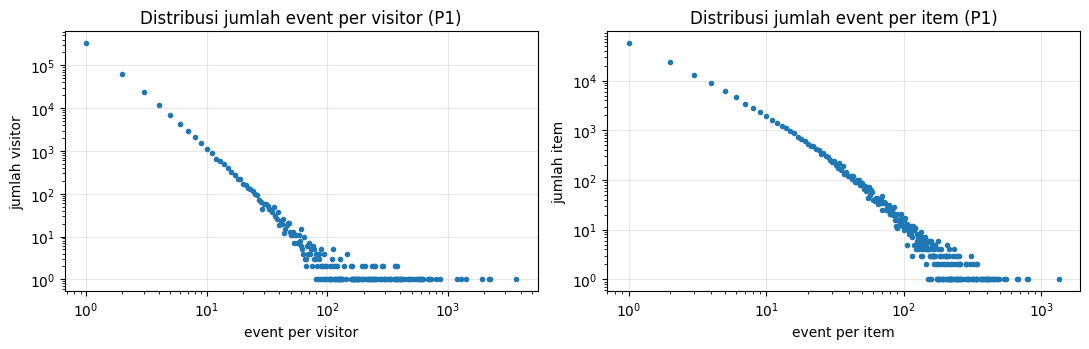

,event,item_unik,transaksi
visitorid,,,
1150086,5101,2584,388
530559,2538,1343,154
371606,2345,1399,94
684514,2245,1187,189
836635,1934,1029,90


In [18]:
p1 = sets["P1"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, name in [(axes[0], "visitorid", "visitor"), (axes[1], "itemid", "item")]:
    freq = p1.groupby(col).size().value_counts().sort_index()
    ax.loglog(freq.index, freq.values, "o", ms=3)
    ax.set(title=f"Distribusi jumlah event per {name} (P1)", xlabel=f"event per {name}", ylabel=f"jumlah {name}")
plt.tight_layout()
plt.show()

(events.assign(transaksi=events.event.eq("transaction"))
 .groupby("visitorid")
 .agg(event=("event", "size"), item_unik=("itemid", "nunique"), transaksi=("transaksi", "sum"))
 .nlargest(5, "event"))

**Interpretasi.**

- Filter menyisakan **1.193.338 event** (43% data). P1 berisi 872.056 event dari 455.767 visitor dan 142.244 item; P2 berisi 321.282 event dari 176.618 visitor dan 82.053 item. Sebanyak 460 baris duplikat dibuang, dan CSV hasilnya berukuran 45,6 MB.
- Hanya **11.217 visitor** (2,5% visitor P1) muncul lagi di P2, sedangkan 61.002 item (43% item P1) tetap aktif di P2. Mayoritas pengunjung datang sekali, sementara pola item jauh lebih stabil antarperiode.
- Funnel stabil antarperiode (dihitung dari visitor unik per jenis event): visitor yang menambah ke keranjang ±2,6% dari visitor yang melihat produk, dan visitor yang bertransaksi ±31% dari visitor yang menambah ke keranjang.
- Distribusi event per visitor dan per item berekor panjang (hampir lurus di skala log-log): sebagian besar visitor dan item hanya punya 1–2 event, segelintir sangat aktif.

#### Membuat subgraph di Neo4j

In [19]:
n_rels = cypher("MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->() RETURN count(r) AS n").n[0]
if n_rels == len(events):
    print(f"Graf sudah berisi {n_rels:,} relasi interaksi (= jumlah baris CSV); impor dilewati.")
else:
    t0 = time.perf_counter()
    import_events(FILTERED_CSV, reset=True)
    print(f"durasi impor: {time.perf_counter() - t0:.0f} detik")
del raw  # data mentah tidak dipakai lagi

Graf sudah berisi 1,193,338 relasi interaksi (= jumlah baris CSV); impor dilewati.


### 2.1.3 Komposisi subgraph

Komposisi graf diambil lewat Python API (`driver.execute_query` di dalam fungsi `cypher()`):

In [20]:
nodes = cypher("""
MATCH (n)
RETURN labels(n)[0] AS label, count(*) AS jumlah
ORDER BY jumlah DESC
""")
nodes

,label,jumlah
0,Visitor,621168
1,Item,163295


In [21]:
rels = cypher("""
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
RETURN type(r) AS relasi, r.fold AS fold, count(*) AS jumlah
ORDER BY relasi, fold
""")
rels.pivot(index="relasi", columns="fold", values="jumlah").assign(total=lambda d: d.sum(axis=1))

fold,P1,P2,total
relasi,,,
ADDED_TO_CART,21498,8117,29615
BOUGHT,7144,2712,9856
VIEWED,843414,310453,1153867


In [22]:
cypher("""
MATCH (v:Visitor)
WITH EXISTS { (v)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->() WHERE r.fold = 'P1' } AS aktif_P1,
     EXISTS { (v)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->() WHERE r.fold = 'P2' } AS aktif_P2
RETURN 'Visitor' AS label, aktif_P1, aktif_P2, count(*) AS jumlah
UNION ALL
MATCH (i:Item)
WITH EXISTS { (i)<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-() WHERE r.fold = 'P1' } AS aktif_P1,
     EXISTS { (i)<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-() WHERE r.fold = 'P2' } AS aktif_P2
RETURN 'Item' AS label, aktif_P1, aktif_P2, count(*) AS jumlah
""").sort_values(["label", "aktif_P1", "aktif_P2"], ascending=False, ignore_index=True)

,label,aktif_P1,aktif_P2,jumlah
0,Visitor,True,True,11217
1,Visitor,True,False,444550
2,Visitor,False,True,165401
3,Item,True,True,61002
4,Item,True,False,81242
5,Item,False,True,21051


In [23]:
display(cypher("SHOW CONSTRAINTS YIELD name, type, labelsOrTypes, properties RETURN name, type, labelsOrTypes, properties"))

n_by_label = nodes.set_index("label").jumlah
assert n_by_label["Visitor"] == events.visitorid.nunique()
assert n_by_label["Item"] == events.itemid.nunique()
assert rels.jumlah.sum() == len(events)
print("Jumlah simpul dan relasi di graf sama dengan isi CSV hasil filter")

,name,type,labelsOrTypes,properties
0,item_id,NODE_PROPERTY_UNIQUENESS,[Item],[itemId]
1,visitor_id,NODE_PROPERTY_UNIQUENESS,[Visitor],[visitorId]


Jumlah simpul dan relasi di graf sama dengan isi CSV hasil filter


Penjelasan Cypher yang dipakai:

| Query | Penjelasan |
|---|---|
| `MATCH (n) RETURN labels(n)[0] AS label, count(*)` | `MATCH (n)` mengambil semua simpul; `labels(n)[0]` adalah label simpul (tiap simpul punya satu label); `count(*)` mengagregasi dan otomatis mengelompokkan menurut kolom non-agregat (`label`), setara `GROUP BY` di SQL. |
| `MATCH ()-[r:VIEWED\|ADDED_TO_CART\|BOUGHT]->() RETURN type(r), r.fold, count(*)` | pola relasi dengan tiga tipe sekaligus (`\|` = atau); `type(r)` memberi nama tipe relasi dan `r.fold` membaca properti fold, lalu hasilnya dikelompokkan per tipe × fold. |
| `EXISTS { (v)-[r]->() WHERE r.fold = 'P1' }` | subquery eksistensi: bernilai `true` bila simpul punya minimal satu relasi di P1. Dipakai untuk menghitung simpul yang aktif di P1 saja, P2 saja, atau keduanya; `UNION ALL` menggabungkan hasil Visitor dan Item. |
| `SHOW CONSTRAINTS` | menampilkan constraint unik yang dibuat fungsi impor. |

**Interpretasi.** Subgraph berisi **784.463 simpul** dengan dua jenis, yaitu **621.168 `Visitor`** dan **163.295 `Item`** — sama persis dengan jumlah visitor dan item unik di CSV. Relasinya **1.193.338** dengan tiga tipe: `VIEWED` 1.153.867, `ADDED_TO_CART` 29.615, dan `BOUGHT` 9.856 (872.056 di P1, 321.282 di P2). Graf ini **bipartit**: relasi selalu `Visitor → Item`, tidak pernah antar-visitor atau antar-item. Dari sisi fold, 444.550 visitor hanya aktif di P1, 165.401 hanya di P2, dan 11.217 di keduanya; untuk item, 81.242 hanya di P1, 21.051 hanya di P2, dan 61.002 di keduanya.



### 2.1.4 Vector Space Modelling simpul User

Dalam *Vector Space Model*, setiap objek direpresentasikan sebagai vektor di ruang berdimensi tinggi, seperti dokumen sebagai vektor kata. Di sini simpul `Visitor` diasumsikan sebagai **User**: setiap visitor adalah vektor berdimensi **jumlah item**, dan nilainya adalah bobot interaksi terkuat visitor terhadap item tersebut di P1:

| event | bobot |
|---|---|
| view | 1 |
| addtocart | 2 |
| transaction | 3 |

Bobotnya ordinal, mengikuti kekuatan niat beli. Hanya P1 (training) yang dipakai; P2 disimpan untuk evaluasi. Data diambil langsung dari graf Neo4j lewat Cypher.

In [24]:
pairs = cypher("""
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.fold = 'P1'
RETURN v.visitorId AS visitorid, i.itemId AS itemid,
       max(CASE type(r) WHEN 'BOUGHT' THEN 3 WHEN 'ADDED_TO_CART' THEN 2 ELSE 1 END) AS w
""")
users = np.sort(pairs.visitorid.unique())
items = np.sort(pairs.itemid.unique())
u_index, i_index = pd.Index(users), pd.Index(items)

# VSM user: baris = visitor, kolom (dimensi) = item, nilai = bobot interaksi terkuat
X = sp.csr_matrix(
    (pairs.w.to_numpy(dtype=np.float64), (u_index.get_indexer(pairs.visitorid), i_index.get_indexer(pairs.itemid))),
    shape=(len(users), len(items)),
)
print(f"{len(pairs):,} pasangan (visitor, item) unik di P1")

679,753 pasangan (visitor, item) unik di P1


In [25]:
def describe_vsm(M, vector_name, dim_name):
    nnz = np.diff(M.indptr)
    density = M.nnz / (M.shape[0] * M.shape[1])
    return pd.Series({
        "shape (vektor × dimensi)": f"{M.shape[0]:,} × {M.shape[1]:,}",
        "jumlah vektor": f"{M.shape[0]:,} {vector_name}",
        "dimensi tiap vektor": f"{M.shape[1]:,} ({dim_name})",
        "elemen tak-nol (nnz)": f"{M.nnz:,}",
        "density": f"{density:.2e}",
        "sparsity": f"{1 - density:.4%}",
        "memori sparse (CSR)": f"{(M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6:.1f} MB",
        "memori bila dense (float64)": f"{M.shape[0] * M.shape[1] * 8 / 1e9:,.0f} GB",
        "nnz per vektor: rata-rata / median / maks": f"{nnz.mean():.2f} / {np.median(nnz):.0f} / {nnz.max():,}",
        "vektor dengan 1 elemen tak-nol": f"{(nnz == 1).mean():.1%}",
    }, name="nilai").to_frame()


describe_vsm(X, "visitor", "item")

,nilai
shape (vektor × dimensi),"455,767 × 142,244"
jumlah vektor,"455,767 visitor"
dimensi tiap vektor,"142,244 (item)"
elemen tak-nol (nnz),"679,753"
density,1.05e-05
sparsity,99.9990%
memori sparse (CSR),10.0 MB
memori bila dense (float64),519 GB
nnz per vektor: rata-rata / median / maks,"1.49 / 1 / 1,937"
vektor dengan 1 elemen tak-nol,81.0%


In [26]:
display(pd.Series(X.data).value_counts().sort_index().rename_axis("bobot").to_frame("jumlah elemen"))

example_user = users[np.argmax(np.diff(X.indptr) == 4)]  # visitor pertama yang punya 4 item
row = X[u_index.get_loc(example_user)]
print(f"Contoh vektor visitor {example_user}: hanya {row.nnz} elemen tak-nol dari {X.shape[1]:,} dimensi")
pd.DataFrame({"itemId (dimensi)": items[row.indices], "bobot": row.data})

,jumlah elemen
bobot,
1.0,659640
2.0,13321
3.0,6792


Contoh vektor visitor 266: hanya 4 elemen tak-nol dari 142,244 dimensi


,itemId (dimensi),bobot
0,39929,1.0
1,212515,1.0
2,340315,1.0
3,449033,1.0


**Plot networkx.** Sampel kecil diambil di sekitar **item acuan**, yaitu item dengan visitor unik terbanyak di P1, yang juga menjadi *record* acuan di 2.1.7. Isinya 8 visitor acak (seed tetap) yang menyentuh item acuan dan punya 2–6 item, beserta seluruh item mereka. Kiri: graf bipartit, di mana vektor user = sisi ke item-itemnya. Kanan: proyeksi user–user, yaitu dua visitor terhubung bila punya item bersama.

item acuan: 5411 (1,195 visitor unik di P1)


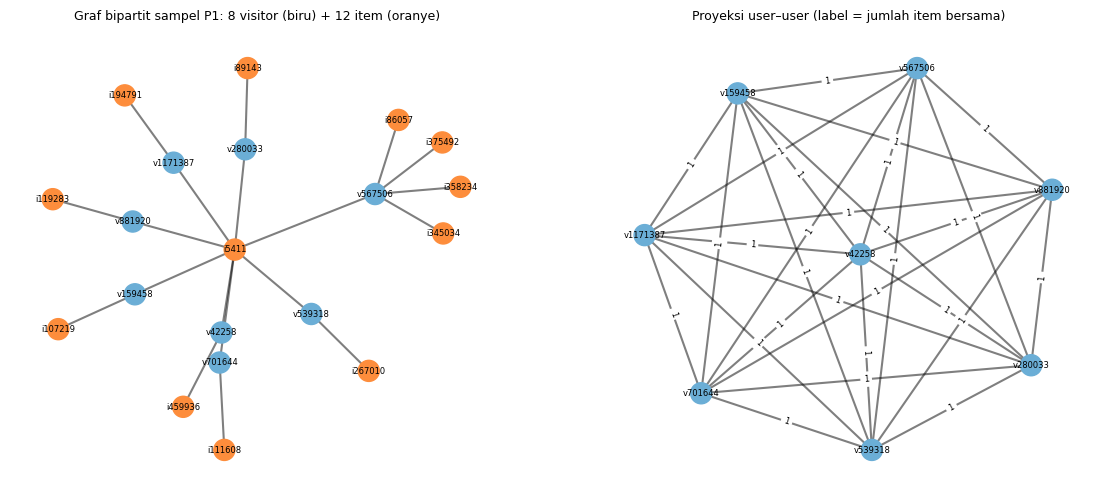

In [27]:
COLORS = {"visitor": "#6baed6", "item": "#fd8d3c"}


def draw(G, ax, title, edge_labels=False):
    """Gambar graf kecil: warna simpul menurut jenis, tebal sisi menurut bobot."""
    pos = nx.spring_layout(G, seed=SEED)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=230, node_color=[COLORS[G.nodes[n]["kind"]] for n in G])
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.5, width=[0.5 + G.edges[e].get("weight", 1) for e in G.edges])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
    if edge_labels:
        nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=6, edge_labels=nx.get_edge_attributes(G, "weight"))
    ax.set_title(title, fontsize=9)
    ax.axis("off")


Xc = X.tocsc()
ref_col = int(np.argmax(np.diff(Xc.indptr)))  # visitor unik terbanyak; seri → itemId terkecil
ref_item = items[ref_col]
ref_rows = Xc.indices[Xc.indptr[ref_col]:Xc.indptr[ref_col + 1]]
n_items_of = np.diff(X.indptr)
candidates = np.sort(ref_rows[(n_items_of[ref_rows] >= 2) & (n_items_of[ref_rows] <= 6)])
sample_rows = np.random.default_rng(SEED).choice(candidates, size=8, replace=False)

Bs = nx.Graph()
for r in sample_rows:
    for c, w in zip(X.indices[X.indptr[r]:X.indptr[r + 1]], X.data[X.indptr[r]:X.indptr[r + 1]]):
        Bs.add_node(f"v{users[r]}", kind="visitor")
        Bs.add_node(f"i{items[c]}", kind="item")
        Bs.add_edge(f"v{users[r]}", f"i{items[c]}", weight=w)
visitor_nodes = [n for n, d in Bs.nodes(data=True) if d["kind"] == "visitor"]
item_nodes = [n for n, d in Bs.nodes(data=True) if d["kind"] == "item"]

print(f"item acuan: {ref_item} ({len(ref_rows):,} visitor unik di P1)")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw(Bs, axes[0], f"Graf bipartit sampel P1: {len(visitor_nodes)} visitor (biru) + {len(item_nodes)} item (oranye)")
draw(nx.bipartite.weighted_projected_graph(Bs, visitor_nodes), axes[1],
     "Proyeksi user–user (label = jumlah item bersama)", edge_labels=True)
plt.show()

**Interpretasi VSM user.**

- **Dimensi** tiap vektor user = 142.244 (jumlah item di P1); **shape** matriks 455.767 × 142.244.
- **Sangat sparse:** hanya 679.753 elemen tak-nol (density 1,05×10⁻⁵). Format CSR cukup 10 MB, padahal bentuk dense butuh ±519 GB.
- Rata-rata visitor hanya punya **1,49 item** (median 1), dan **81% vektor user hanya punya satu elemen tak-nol**. Contohnya, visitor 266 hanya mengisi 4 dari 142.244 dimensi.
- Bobot didominasi view: 659.640 elemen bernilai 1, 13.321 bernilai 2, dan 6.792 bernilai 3.
- Plot networkx: graf bipartit sampel berbentuk bintang di sekitar item 5411 karena semua visitor sampel menyentuhnya. Pada proyeksi user–user, ke-8 visitor itu otomatis saling terhubung menjadi klik K₈. **Setiap item membuat semua penggunanya saling terhubung**, sehingga item populer dengan ribuan pengguna menghasilkan klik raksasa — sumber mahalnya proyeksi user.



### 2.1.5 Vector Space Modelling simpul Item

Kebalikannya, simpul `Item` menjadi vektor berdimensi **jumlah visitor**. Matriks VSM item adalah transpos VSM user (`Xᵀ`).

In [28]:
Xi = X.T.tocsr()  # VSM item: baris = item, kolom (dimensi) = visitor
describe_vsm(Xi, "item", "visitor")

,nilai
shape (vektor × dimensi),"142,244 × 455,767"
jumlah vektor,"142,244 item"
dimensi tiap vektor,"455,767 (visitor)"
elemen tak-nol (nnz),"679,753"
density,1.05e-05
sparsity,99.9990%
memori sparse (CSR),8.7 MB
memori bila dense (float64),519 GB
nnz per vektor: rata-rata / median / maks,"4.78 / 2 / 1,195"
vektor dengan 1 elemen tak-nol,44.5%


In [29]:
ref_vec = Xi[ref_col]
print(f"Vektor item acuan {ref_item}: {ref_vec.nnz:,} elemen tak-nol dari {Xi.shape[1]:,} dimensi")
pd.Series(ref_vec.data).value_counts().sort_index().rename_axis("bobot").to_frame("jumlah visitor")

Vektor item acuan 5411: 1,195 elemen tak-nol dari 455,767 dimensi


,jumlah visitor
bobot,
1.0,1190
2.0,5


Kiri: proyeksi item–item dari sampel bipartit yang sama — dua item terhubung bila disentuh visitor yang sama. Kanan: sebaran jumlah elemen tak-nol per vektor pada kedua VSM.

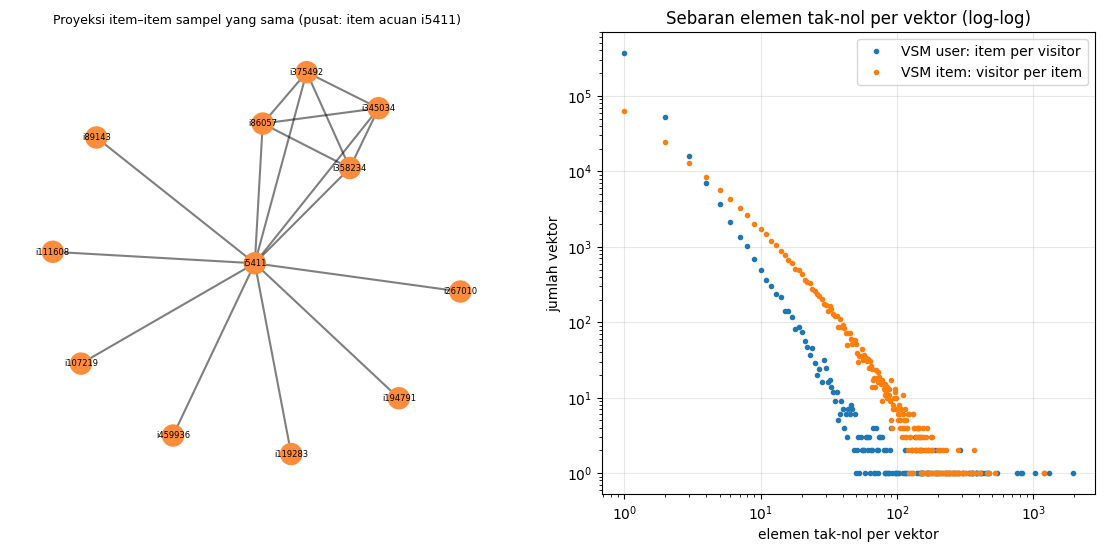

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw(nx.bipartite.weighted_projected_graph(Bs, item_nodes), axes[0],
     f"Proyeksi item–item sampel yang sama (pusat: item acuan i{ref_item})")
for M, label in [(X, "VSM user: item per visitor"), (Xi, "VSM item: visitor per item")]:
    freq = pd.Series(np.diff(M.indptr)).value_counts().sort_index()
    axes[1].loglog(freq.index, freq.values, "o", ms=3, label=label)
axes[1].set(title="Sebaran elemen tak-nol per vektor (log-log)", xlabel="elemen tak-nol per vektor",
            ylabel="jumlah vektor")
axes[1].legend()
plt.show()

**Interpretasi VSM item.**

- **Dimensi** tiap vektor item = 455.767 (jumlah visitor di P1); **shape** 142.244 × 455.767 — transpos VSM user dengan nnz yang sama (679.753).
- Vektor item jauh lebih berisi: rata-rata **4,78 visitor per item** (median 2, maksimum 1.195 pada item acuan 5411). Hanya **44,5%** vektor item yang punya satu elemen tak-nol, dibanding 81% pada VSM user.
- Pada plot log-log, titik oranye (item) berada di atas titik biru (user) di rentang menengah, artinya lebih banyak item yang punya puluhan hingga ratusan interaksi.
- Pada proyeksi item–item sampel, item acuan 5411 menjadi hub, dan item milik visitor yang sama (misalnya visitor 567506) membentuk klik kecil.



### 2.1.6 Proyeksi mana yang lebih baik?

Kedua proyeksi satu-mode dihitung **secara utuh** dari matriks biner `B` (1 bila visitor menyentuh item). Proyeksi user–user = `B·Bᵀ` dan proyeksi item–item = `Bᵀ·B`; nilai tiap sel = jumlah tetangga bersama. Ukuran yang dibandingkan:

- **efisiensi:** jumlah node dan edge, waktu hitung, dan memori;
- **efektivitas:** kerapatan informasi tiap vektor, yaitu rata-rata derajat, proporsi simpul terisolasi, dan proporsi vektor *degenerate* (hanya 1 elemen tak-nol).

In [31]:
def projection_stats(M, name):
    """Proyeksi satu-mode B·Bᵀ (B = M biner, diagonal dibuang) beserta ukuran biayanya."""
    B = (M > 0).astype(np.float32)
    t0 = time.perf_counter()
    P = (B @ B.T).tocsr()
    P.setdiag(0)
    P.eliminate_zeros()
    seconds = time.perf_counter() - t0
    n, m = P.shape[0], P.nnz // 2
    return {
        "proyeksi": name,
        "node": f"{n:,}",
        "edge": f"{m:,}",
        "densitas": f"{m / (n * (n - 1) / 2):.2e}",
        "rata-rata derajat": f"{2 * m / n:.1f}",
        "node terisolasi": f"{(np.diff(P.indptr) == 0).mean():.1%}",
        "vektor degenerate (1 elemen)": f"{(np.diff(M.indptr) == 1).mean():.1%}",
        "waktu hitung": f"{seconds:.2f} detik",
        "memori": f"{(P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1e6:.0f} MB",
    }


pd.DataFrame([projection_stats(X, "user–user"), projection_stats(Xi, "item–item")]).set_index("proyeksi").T

proyeksi,user–user,item–item
node,"455,767","142,244"
edge,"10,265,403","7,760,995"
densitas,9.88e-05,7.67e-04
rata-rata derajat,45.0,109.1
node terisolasi,9.0%,42.2%
vektor degenerate (1 elemen),81.0%,44.5%
waktu hitung,0.89 detik,0.45 detik
memori,166 MB,125 MB


In [32]:
d = np.diff(X.indptr).astype(np.int64)
pairs_top = d.max() * (d.max() - 1) // 2
print(f"Visitor teraktif menyentuh {d.max():,} item sehingga membentuk {pairs_top:,} pasangan item "
      f"= {pairs_top / (d * (d - 1) // 2).sum():.0%} dari seluruh pasangan item (sebelum digabung).")

Visitor teraktif menyentuh 1,937 item sehingga membentuk 1,875,016 pasangan item = 22% dari seluruh pasangan item (sebelum digabung).


**Kesimpulan 2.1.6 — proyeksi item–item lebih baik.**

| Aspek | user–user | item–item |
|---|---|---|
| Node | 455.767 | **142.244** (3,2× lebih sedikit) |
| Edge | 10.265.403 | **7.760.995** (24% lebih sedikit) |
| Waktu hitung | ±0,8 detik | **±0,6 detik** |
| Memori | 166 MB | **125 MB** |
| Rata-rata derajat | 45,0 | 109,1 |
| Vektor degenerate | 81,0% | **44,5%** |
| Node terisolasi | **9,0%** | 42,2% |

- **Efisien:** proyeksi item lebih kecil di semua ukuran biaya. Selain itu, item berubah lebih lambat daripada user, sehingga graf similarity item cukup dihitung sekali lalu dipakai berulang. User-KNN harus mencari tetangga di antara 455 ribu user untuk setiap permintaan.
- **Efektif:** proyeksi user tampak lebih terhubung (hanya 9% terisolasi), tetapi kualitasnya rendah. Karena 81% user hanya punya satu item, kemiripan antar-user praktis ditentukan oleh **satu item bersama**, dan tetangga terdekat sering tidak membawa item baru (lihat pembanding user-KNN di 2.2.1). Vektor item rata-rata 3,2× lebih padat, sehingga cosine-nya lebih bermakna.
- **Bukti empiris** di 2.2.3: item-KNN mencapai Hit@5 0,0383, sedangkan user-KNN 0,0251.




### 2.1.7 Similarity pada graf terproyeksi (item–item)

Similarity dihitung di Python dengan **cosine similarity** antar vektor item:

$$\cos(i,j) = \frac{\sum_u w_{ui}\, w_{uj}}{\lVert \mathbf{x}_i \rVert \, \lVert \mathbf{x}_j \rVert}$$

Pasangan item yang hanya didukung **satu** visitor bersama dipangkas (**support ≥ 2**). Kecocokan dari satu orang mudah terjadi secara kebetulan, terutama dari visitor super-aktif yang menyentuh ribuan item. Hasilnya disimpan sebagai **graf KNN**: setiap item menyimpan k = 5 tetangga dengan skor tertinggi (bila seri, `itemId` lebih kecil didahulukan).

In [33]:
# cosine item–item = perkalian titik vektor item yang sudah dinormalisasi L2
norms = np.sqrt(np.asarray(Xi.multiply(Xi).sum(axis=1)).ravel())
Xn = (sp.diags(1 / norms) @ Xi).tocsr()
S = (Xn @ Xn.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()

# support = jumlah visitor bersama; pasangan dengan support < 2 dipangkas
Bi = (Xi > 0).astype(np.float64)
C = (Bi @ Bi.T).tocsr()
S_pruned = S.multiply(C >= 2).tocsr()
S_pruned.eliminate_zeros()

print(f"pasangan item dengan cosine > 0   : {S.nnz // 2:,}")
print(f"setelah pruning support ≥ 2       : {S_pruned.nnz // 2:,}")
print(f"item yang punya ≥ 1 tetangga      : {(np.diff(S_pruned.indptr) > 0).mean():.1%} "
      f"(tanpa pruning {(np.diff(S.indptr) > 0).mean():.1%})")

pasangan item dengan cosine > 0   : 7,760,995
setelah pruning support ≥ 2       : 493,924
item yang punya ≥ 1 tetangga      : 16.6% (tanpa pruning 57.8%)


In [34]:
def top_k_neighbors(S, k=K):
    rows = []
    for r in range(S.shape[0]):
        cols, vals = S.indices[S.indptr[r]:S.indptr[r + 1]], S.data[S.indptr[r]:S.indptr[r + 1]]
        for rank, j in enumerate(np.lexsort((items[cols], -vals))[:k], start=1):
            rows.append((items[r], items[cols[j]], vals[j], rank))
    return pd.DataFrame(rows, columns=["source", "target", "score", "rank"])


knn = top_k_neighbors(S_pruned)
knn["support"] = np.asarray(C[i_index.get_indexer(knn.source), i_index.get_indexer(knn.target)]).ravel().astype(int)
print(f"graf KNN: {len(knn):,} relasi dari {knn.source.nunique():,} item sumber")

py_top5 = knn[knn.source == ref_item].reset_index(drop=True)
print(f"record acuan: item {ref_item} (visitor unik terbanyak di P1)")
py_top5

graf KNN: 77,316 relasi dari 23,682 item sumber
record acuan: item 5411 (visitor unik terbanyak di P1)


,source,target,score,rank,support
0,5411,33030,0.145548,1,45
1,5411,33956,0.092333,2,14
2,5411,358234,0.088607,3,19
3,5411,37807,0.079678,4,12
4,5411,459936,0.067019,5,25


#### (a) Cypher untuk 5 record dengan similarity tertinggi

Query berikut menghitung ulang cosine **langsung di Neo4j** dari graf bipartit untuk item acuan, lalu mengambil 5 teratas. Hasilnya harus sama dengan perhitungan Python di atas.

| Langkah | Penjelasan |
|---|---|
| `MATCH (ref)<-[r1]-(v:Visitor)` + `max(CASE ...)` | visitor yang menyentuh item acuan di P1 beserta bobot terkuatnya (`w_ref`) |
| `MATCH (v)-[r2]->(other:Item)` | item lain yang disentuh visitor yang sama — inilah sisi proyeksi item–item |
| `sum(w_ref * w_other) AS dot`, `count(v) AS support` | pembilang cosine dan jumlah visitor bersama; `WHERE support >= 2` adalah pruning |
| `CALL (ref) {...}`, `CALL (other) {...}` | norma vektor tiap item, yaitu `sqrt(Σ w²)` |
| `ORDER BY cosine DESC, itemId ASC LIMIT 5` | 5 tertinggi dengan aturan seri yang sama seperti di Python |

In [35]:
COSINE_TOP5 = """
MATCH (ref:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WHERE r1.fold = 'P1'
WITH ref, v, max(CASE type(r1) WHEN 'BOUGHT' THEN 3 WHEN 'ADDED_TO_CART' THEN 2 ELSE 1 END) AS w_ref
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE r2.fold = 'P1' AND other <> ref
WITH ref, other, v, w_ref, max(CASE type(r2) WHEN 'BOUGHT' THEN 3 WHEN 'ADDED_TO_CART' THEN 2 ELSE 1 END) AS w_other
WITH ref, other, sum(w_ref * w_other) AS dot, count(v) AS support
WHERE support >= 2
CALL (ref) {
  MATCH (ref)<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor) WHERE r.fold = 'P1'
  WITH u, max(CASE type(r) WHEN 'BOUGHT' THEN 3 WHEN 'ADDED_TO_CART' THEN 2 ELSE 1 END) AS w
  RETURN sqrt(sum(w * w)) AS norm_ref
}
CALL (other) {
  MATCH (other)<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor) WHERE r.fold = 'P1'
  WITH u, max(CASE type(r) WHEN 'BOUGHT' THEN 3 WHEN 'ADDED_TO_CART' THEN 2 ELSE 1 END) AS w
  RETURN sqrt(sum(w * w)) AS norm_other
}
RETURN other.itemId AS itemId, support, dot / (norm_ref * norm_other) AS cosine
ORDER BY cosine DESC, itemId ASC
LIMIT 5
"""
cy_top5 = cypher(COSINE_TOP5, ref=int(ref_item))
display(cy_top5)

assert list(cy_top5.itemId) == list(py_top5.target)
assert list(cy_top5.support) == list(py_top5.support)
assert np.allclose(cy_top5.cosine, py_top5.score, atol=1e-9)
print("Top-5 hasil Cypher identik dengan hasil Python")

,itemId,support,cosine
0,33030,45,0.145548
1,33956,14,0.092333
2,358234,19,0.088607
3,37807,12,0.079678
4,459936,25,0.067019


Top-5 hasil Cypher identik dengan hasil Python


#### (b) Menulis kembali similarity ke graf

Seluruh graf KNN (5 tetangga per item) ditulis ke Neo4j sebagai relasi `(:Item)-[:SIMILAR {score, support, rank, method, fold}]->(:Item)` dengan `UNWIND` per batch 10.000 baris. Relasi `SIMILAR` lama dihapus dulu supaya notebook bisa dijalankan ulang. Sebelum menulis, kondisi graf di sekitar item acuan direkam lewat query `SNAPSHOT`, yang dipakai lagi di 2.1.8.

In [36]:
SNAPSHOT = """
MATCH (ref:Item {itemId: $ref})
MATCH (o:Item) WHERE o.itemId IN $targets
OPTIONAL MATCH (ref)-[s:SIMILAR]->(o)
CALL (ref, o) {
  MATCH (ref)<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o)
  WHERE r1.fold = 'P1' AND r2.fold = 'P1'
  WITH DISTINCT v ORDER BY v.visitorId
  RETURN collect(v.visitorId)[..3] AS visitor_bersama
}
RETURN o.itemId AS item, visitor_bersama, s.score AS similar_score
ORDER BY item
"""
WRITE_SIMILAR = """
UNWIND $rows AS row
MATCH (a:Item {itemId: row.source})
MATCH (b:Item {itemId: row.target})
CREATE (a)-[:SIMILAR {score: row.score, support: row.support, rank: row.rank,
                      method: 'cosine', fold: 'P1'}]->(b)
"""

cypher("MATCH ()-[s:SIMILAR]->() DELETE s")  # bersihkan hasil eksekusi sebelumnya
targets = [int(t) for t in py_top5.target]
before = cypher(SNAPSHOT, ref=int(ref_item), targets=targets)
n_similar_before = cypher("MATCH ()-[s:SIMILAR]->() RETURN count(s) AS n").n[0]

records = knn.astype({"source": int, "target": int, "rank": int, "support": int}).to_dict("records")
for start in range(0, len(records), 10_000):
    cypher(WRITE_SIMILAR, rows=records[start:start + 10_000])
print(f"{len(records):,} relasi SIMILAR ditulis ke database {DB}")

77,316 relasi SIMILAR ditulis ke database midterm-exam


Hasil query setelah similarity ditulis kembali, top-5 item acuan kini dibaca langsung dari relasi `SIMILAR`, ditambah ringkasan seluruh relasi `SIMILAR`:

In [37]:
display(cypher("""
MATCH (a:Item {itemId: $ref})-[s:SIMILAR]->(b:Item)
RETURN b.itemId AS itemId, s.rank AS rank, s.score AS score, s.support AS support
ORDER BY s.rank
""", ref=int(ref_item)))
cypher("""
MATCH (a:Item)-[s:SIMILAR]->(:Item)
RETURN count(s) AS jumlah_relasi, count(DISTINCT a) AS item_sumber,
       round(avg(s.score), 4) AS skor_rata2, round(min(s.score), 4) AS skor_min, round(max(s.score), 4) AS skor_maks
""")

,itemId,rank,score,support
0,33030,1,0.145548,45
1,33956,2,0.092333,14
2,358234,3,0.088607,19
3,37807,4,0.079678,12
4,459936,5,0.067019,25


,jumlah_relasi,item_sumber,skor_rata2,skor_min,skor_maks
0,77316,23682,0.2657,0.008,1.0


**Interpretasi.**

- Dari 7.760.995 pasangan item bersimilarity > 0, hanya **493.924** yang didukung ≥ 2 visitor bersama. Pruning membuang 94% pasangan yang rapuh, dengan konsekuensi hanya 16,6% item (23.682) yang punya tetangga.
- Graf KNN akhir berisi **77.316 relasi `SIMILAR`** (paling banyak 5 per item), dengan skor rata-rata 0,266 dan rentang 0,008–1,0.
- Item acuan **5411** (1.195 visitor) paling mirip dengan **33030** (cosine 0,146; 45 visitor bersama), lalu 33956 (0,092), 358234 (0,089), 37807 (0,080), dan 459936 (0,067). Skor item populer relatif kecil karena normanya besar: cosine mengukur proporsi visitor bersama, bukan jumlahnya.
- Cypher yang menghitung langsung di graf memberi 5 item, support, dan skor yang identik dengan Python (assert lolos). Setelah ditulis kembali, query ke relasi `SIMILAR` mengembalikan nilai yang sama.



### 2.1.8 Kondisi sebelum dan sesudah perhitungan similarity

Query `SNAPSHOT` yang sama dijalankan sebelum (sudah direkam di 2.1.7b) dan sesudah relasi `SIMILAR` ditulis:

```cypher
MATCH (ref:Item {itemId: $ref})
MATCH (o:Item) WHERE o.itemId IN $targets             // 5 item paling mirip
OPTIONAL MATCH (ref)-[s:SIMILAR]->(o)                  // null sebelum similarity ditulis
CALL (ref, o) {                                        // maks. 3 visitor bersama (konteks bipartit)
  MATCH (ref)<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o)
  WHERE r1.fold = 'P1' AND r2.fold = 'P1'
  WITH DISTINCT v ORDER BY v.visitorId
  RETURN collect(v.visitorId)[..3] AS visitor_bersama
}
RETURN o.itemId AS item, visitor_bersama, s.score AS similar_score
ORDER BY item
```

In [38]:
after = cypher(SNAPSHOT, ref=int(ref_item), targets=targets)
n_similar_after = cypher("MATCH ()-[s:SIMILAR]->() RETURN count(s) AS n").n[0]
print(f"jumlah relasi SIMILAR di graf: sebelum = {n_similar_before:,}, sesudah = {n_similar_after:,}")
pd.concat({"sebelum": before.set_index("item"), "sesudah": after.set_index("item")}, axis=1)

jumlah relasi SIMILAR di graf: sebelum = 0, sesudah = 77,316


sebelum                                 sesudah              
                 visitor_bersama similar_score           visitor_bersama similar_score
item                                                                                  
33030    [14955, 179880, 206451]          None   [14955, 179880, 206451]      0.145548
33956   [179337, 519209, 526636]          None  [179337, 519209, 526636]      0.092333
37807     [21861, 61935, 206451]          None    [21861, 61935, 206451]      0.079678
358234    [7883, 206451, 237769]          None    [7883, 206451, 237769]      0.088607
459936   [42258, 184093, 308826]          None   [42258, 184093, 308826]      0.067019

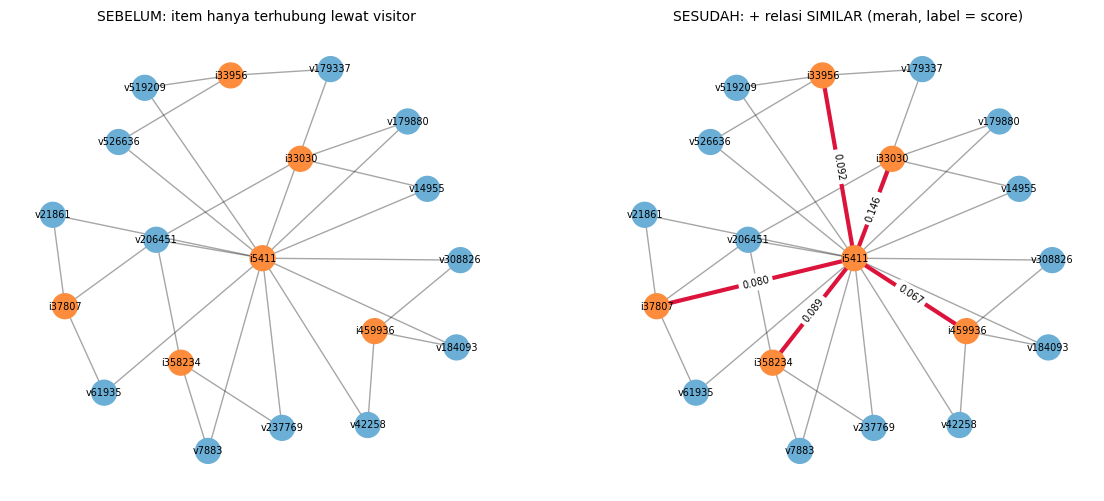

In [39]:
def snapshot_graph(snap):
    """Bangun graf networkx dari hasil SNAPSHOT: item acuan, 5 item mirip, visitor bersama, dan SIMILAR."""
    G = nx.Graph()
    ref = f"i{ref_item}"
    G.add_node(ref, kind="item")
    for row in snap.itertuples():
        o = f"i{row.item}"
        G.add_node(o, kind="item")
        for v in row.visitor_bersama:
            G.add_node(f"v{v}", kind="visitor")
            G.add_edge(f"v{v}", ref, kind="interaksi")
            G.add_edge(f"v{v}", o, kind="interaksi")
        if pd.notna(row.similar_score):
            G.add_edge(ref, o, kind="SIMILAR", score=row.similar_score)
    return G


G_before, G_after = snapshot_graph(before), snapshot_graph(after)
pos = nx.kamada_kawai_layout(G_after)  # posisi sama untuk kedua panel
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, G, title in [(axes[0], G_before, "SEBELUM: item hanya terhubung lewat visitor"),
                     (axes[1], G_after, "SESUDAH: + relasi SIMILAR (merah, label = score)")]:
    interaksi = [e for e in G.edges if G.edges[e]["kind"] == "interaksi"]
    similar = [e for e in G.edges if G.edges[e]["kind"] == "SIMILAR"]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=320, node_color=[COLORS[G.nodes[n]["kind"]] for n in G])
    nx.draw_networkx_edges(G, pos, edgelist=interaksi, ax=ax, alpha=0.35)
    nx.draw_networkx_edges(G, pos, edgelist=similar, ax=ax, width=3, edge_color="crimson")
    nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=7,
                                 edge_labels={e: f"{G.edges[e]['score']:.3f}" for e in similar})
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

**Interpretasi.** Sebelum similarity ditulis, item acuan dan 5 item termiripnya **hanya terhubung tidak langsung** lewat visitor (pola `Item ← Visitor → Item`, dua langkah), dan graf belum punya satu pun relasi `SIMILAR`. Sesudahnya, graf punya 77.316 relasi `SIMILAR`, dan item acuan **terhubung langsung** (satu langkah) ke 5 tetangganya dengan skor sebagai properti relasi. Konteks bipartitnya tidak berubah — visitor bersama yang sama tetap ada — hanya bertambah lapisan relasi baru di atasnya. Rekomendasi kini bisa dijawab dengan traversal pendek `(:Item)-[:SIMILAR]->(:Item)` tanpa menghitung ulang similarity.


## 2.2 Analytics

### 2.2.1 Pemilihan user acak dan rekomendasi KNN

**Proses acak yang reproducible:**

1. *Pool* kandidat berisi visitor yang memenuhi dua syarat:
   - menyentuh ≥ 3 item berbeda di P1, supaya punya riwayat untuk KNN;
   - di P2 menyentuh minimal satu item **baru** (tidak ada di riwayat P1-nya) yang **ada di graf P1**, supaya rekomendasinya bisa dievaluasi. Item yang tidak pernah muncul di P1 mustahil direkomendasikan.
2. Pool diurutkan menurut `visitorId` agar urutannya tetap.
3. Satu indeks diundi dengan `numpy.random.default_rng(SEED)`, `SEED = 2026`. Seed ditetapkan sebelum melihat hasil dan tidak diundi ulang.

Siapa pun yang menjalankan ulang notebook dengan data dan seed yang sama akan mendapat user yang sama.

In [40]:
def user_history(u):
    """H(u): item yang disentuh visitor u di P1 beserta bobotnya (dibaca dari VSM user X)."""
    r = u_index.get_loc(u)
    sl = slice(X.indptr[r], X.indptr[r + 1])
    return dict(zip(items[X.indices[sl]], X.data[sl]))


p2_pairs = cypher("""
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.fold = 'P2'
RETURN DISTINCT v.visitorId AS visitorid, i.itemId AS itemid
""")
n_hist = pd.Series(np.diff(X.indptr), index=users)
returning = p2_pairs[p2_pairs.visitorid.map(n_hist).fillna(0) >= 3]

# R(u): item P2 yang belum ada di riwayat P1 (ground truth evaluasi)
relevant = {u: set(g.itemid) - set(user_history(u)) for u, g in returning.groupby("visitorid")}
item_set = set(items)
pool = sorted(u for u, rel in relevant.items() if rel & item_set)

rng = np.random.default_rng(SEED)
user = pool[rng.integers(len(pool))]
print(f"pool eligible: {len(pool):,} visitor → visitor terpilih: {user} (seed {SEED})")

pool eligible: 2,034 visitor → visitor terpilih: 1174645 (seed 2026)


Riwayat P1 user terpilih, dibaca dari graf:

In [41]:
cypher("""
MATCH (v:Visitor {visitorId: $uid})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.fold = 'P1'
RETURN i.itemId AS itemId, collect(type(r)) AS event,
       max(CASE type(r) WHEN 'BOUGHT' THEN 3 WHEN 'ADDED_TO_CART' THEN 2 ELSE 1 END) AS bobot
ORDER BY bobot DESC, itemId
""", uid=int(user))

,itemId,event,bobot
0,347239,[VIEWED],1
1,384843,[VIEWED],1
2,439539,"[VIEWED, VIEWED]",1


#### (a) Skrip Python rekomendasi KNN

Dipakai **item-based KNN**, konsisten dengan kesimpulan 2.1.6. Untuk user `u` dengan riwayat `H(u)`:

$$\text{score}(j) = \sum_{i \in H(u),\; j \in N_5(i)} w_{ui}\cdot \cos(i,j), \qquad j \notin H(u)$$

`N₅(i)` adalah 5 tetangga terdekat item `i` di graf KNN (k = 5). Kandidat diurutkan menurut skor dan 5 teratas menjadi daftar rekomendasi. Bila kandidat kurang dari 5, sisa slot diisi item terpopuler P1 yang belum dilihat (*fallback*).

In [42]:
neighbors = {s: list(zip(g.target, g.score)) for s, g in knn.groupby("source")}
popular = items[np.lexsort((items, -np.diff(Xi.indptr)))]  # visitor unik terbanyak dulu


def finalize(ranked, hist, n=5):
    """Susun top-n; bila kandidat kurang dari n, isi dengan item terpopuler P1 yang belum dilihat."""
    rows = [(j, s, "KNN") for j, s in ranked[:n]]
    taken = {j for j, _, _ in rows} | set(hist)
    for j in popular:
        if len(rows) == n:
            break
        if j not in taken:
            rows.append((j, 0.0, "fallback popularitas"))
    return pd.DataFrame(rows, columns=["itemId", "score", "sumber"],
                        index=pd.RangeIndex(1, len(rows) + 1, name="rank"))


def recommend_item_knn(u, neighbors=neighbors, n=5):
    """Item-based KNN: setiap item riwayat menyumbang skor ke k tetangganya."""
    hist = user_history(u)
    scores = {}
    for i, w in hist.items():
        for j, sim in neighbors.get(i, []):
            if j not in hist:
                scores[j] = scores.get(j, 0.0) + w * sim
    return finalize(sorted(scores.items(), key=lambda t: (-t[1], t[0])), hist, n)

#### (b) 3 item yang diiklankan (k = 5)

In [43]:
recs = recommend_item_knn(user)
ads = recs.head(3)
display(recs)
print("3 item yang diiklankan:", ", ".join(str(j) for j in ads.itemId))

,itemId,score,sumber
rank,,,
1,294965,0.258199,KNN
2,194958,0.147314,KNN
3,244571,0.129904,KNN
4,135490,0.129099,KNN
5,215355,0.109109,KNN


3 item yang diiklankan: 294965, 194958, 244571


Asal skor tiap rekomendasi — pasangan item riwayat → item rekomendasi di graf KNN:

In [44]:
hist = user_history(user)
contrib = knn[knn.source.isin(list(hist)) & knn.target.isin(recs.itemId)].copy()
contrib["bobot riwayat"] = contrib.source.map(hist)
contrib["kontribusi"] = contrib["bobot riwayat"] * contrib.score
contrib.rename(columns={"source": "item riwayat", "target": "item rekomendasi"}).sort_values(
    ["item rekomendasi", "kontribusi"], ascending=[True, False])

,item riwayat,item rekomendasi,score,rank,support,bobot riwayat,kontribusi
72891,439539,135490,0.129099,4,3,1.0,0.129099
72889,439539,194958,0.147314,2,4,1.0,0.147314
72892,439539,215355,0.109109,5,2,1.0,0.109109
72890,439539,244571,0.129904,3,6,1.0,0.129904
72888,439539,294965,0.258199,1,2,1.0,0.258199


Rekomendasi yang sama bisa diperoleh langsung dari graf dengan menelusuri relasi `SIMILAR`. Hasilnya dicek sama dengan skrip Python:

In [45]:
cy_recs = cypher("""
MATCH (u:Visitor {visitorId: $uid})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.fold = 'P1'
WITH u, i, max(CASE type(r) WHEN 'BOUGHT' THEN 3 WHEN 'ADDED_TO_CART' THEN 2 ELSE 1 END) AS w
MATCH (i)-[s:SIMILAR]->(rec:Item)
WHERE NOT EXISTS { (u)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(rec) WHERE r2.fold = 'P1' }
RETURN rec.itemId AS itemId, sum(w * s.score) AS score
ORDER BY score DESC, itemId ASC
LIMIT 5
""", uid=int(user))
display(cy_recs)

knn_part = recs[recs.sumber == "KNN"]
assert list(cy_recs.itemId) == list(knn_part.itemId)
assert np.allclose(cy_recs.score, knn_part.score)
print("Rekomendasi dari Cypher (relasi SIMILAR) identik dengan skrip Python ✔")

,itemId,score
0,294965,0.258199
1,194958,0.147314
2,244571,0.129904
3,135490,0.129099
4,215355,0.109109


Rekomendasi dari Cypher (relasi SIMILAR) identik dengan skrip Python ✔


Sebagai pembanding, **user-based KNN** untuk user yang sama: cari 5 visitor paling mirip menurut cosine VSM user, lalu `score(j) = Σ cos(u,v)·w_vj`.

In [46]:
norms_u = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
Xun = (sp.diags(1 / norms_u) @ X).tocsr()


def recommend_user_knn(u, k=K, n=5):
    """User-based KNN: k visitor paling mirip (cosine VSM user) menyumbang skor ke item mereka."""
    r = u_index.get_loc(u)
    sims = (Xun @ Xun[r].T).toarray().ravel()
    sims[r] = 0
    nb = np.argsort(-sims, kind="stable")[:k]
    nb = nb[sims[nb] > 0]
    scores = np.asarray(X[nb].T @ sims[nb]).ravel()
    hist = user_history(u)
    ranked = [(items[j], scores[j]) for j in np.lexsort((items, -scores))[: n + len(hist)]
              if scores[j] > 0 and items[j] not in hist]
    return finalize(ranked, hist, n)


recommend_user_knn(user)

,itemId,score,sumber
rank,,,
1,5411,0.0,fallback popularitas
2,309778,0.0,fallback popularitas
3,370653,0.0,fallback popularitas
4,257040,0.0,fallback popularitas
5,298009,0.0,fallback popularitas


**Interpretasi.**

- Dari 2.034 visitor eligible, seed 2026 memilih **visitor 1174645**. Di P1 ia hanya melihat (`VIEWED`) 3 item: 347239, 384843, dan 439539 (dua kali).
- Hanya item **439539** yang punya tetangga di graf KNN; dua item lainnya tidak punya pasangan dengan dukungan ≥ 2 visitor. Jadi kelima rekomendasi berasal dari 5 tetangga 439539, dengan skor = cosine (bobot view = 1).
- **3 item yang diiklankan: 294965, 194958, 244571**, disusul 135490 dan 215355 di peringkat 4–5.
- Cypher yang menelusuri relasi `SIMILAR` menghasilkan daftar dan skor yang sama dengan skrip Python.
- **Pembanding user-KNN** gagal untuk user ini: kelima rekomendasinya hasil *fallback* popularitas. Seluruh item milik 5 visitor terdekatnya sudah ada di riwayat user, sehingga tidak ada item baru yang bisa disarankan. Ini contoh nyata kelemahan proyeksi user di 2.1.6.


### 2.2.2 Hit@5 dan NDCG@5

Ground truth `R(u)` adalah item yang disentuh user di **P2** dan belum ada di riwayat P1-nya, dengan relevansi biner.

- $\text{Hit@5} = 1$ bila minimal satu dari 5 rekomendasi teratas ada di `R(u)`; selain itu 0.
- $\text{DCG@5} = \sum_{k=1}^{5} \frac{rel_k}{\log_2(k+1)}$, $\quad \text{IDCG@5} = \sum_{k=1}^{\min(|R(u)|,\,5)} \frac{1}{\log_2(k+1)}$, $\quad \text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$.

Metrik dihitung pada daftar 5 rekomendasi teratas, di mana posisi 1–3 adalah item iklan. Karena soal merujuk ke hasil 1b (3 iklan), varian *hanya 3 iklan* (posisi 4–5 kosong) juga dihitung.

In [47]:
def hit_ndcg(rec_items, relevant_items, k=5):
    """Hit@k dan NDCG@k dengan relevansi biner."""
    rel = [int(j in relevant_items) for j in list(rec_items)[:k]]
    dcg = sum(r / np.log2(pos + 2) for pos, r in enumerate(rel))
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(relevant_items), k)))
    return float(any(rel)), dcg / idcg


truth = cypher("""
MATCH (v:Visitor {visitorId: $uid})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.fold = 'P2'
WITH v, i, collect(DISTINCT type(r)) AS event_P2
RETURN i.itemId AS itemId, event_P2,
       EXISTS { (v)-[x:VIEWED|ADDED_TO_CART|BOUGHT]->(i) WHERE x.fold = 'P1' } AS sudah_di_riwayat_P1,
       EXISTS { (i)<-[x:VIEWED|ADDED_TO_CART|BOUGHT]-() WHERE x.fold = 'P1' } AS ada_di_graf_P1
ORDER BY itemId
""", uid=int(user))
R = set(truth.loc[~truth.sudah_di_riwayat_P1, "itemId"])
assert R == relevant[user]
truth

,itemId,event_P2,sudah_di_riwayat_P1,ada_di_graf_P1
0,294956,[VIEWED],False,True
1,361463,[VIEWED],False,True


In [48]:
steps = recs.assign(relevan=recs.itemId.isin(R).astype(int))
steps["diskon 1/log2(rank+1)"] = 1 / np.log2(steps.index + 1)
steps["kontribusi DCG"] = steps.relevan * steps["diskon 1/log2(rank+1)"]
display(steps)

hit5, ndcg5 = hit_ndcg(recs.itemId, R)
idcg5 = sum(1 / np.log2(p + 2) for p in range(min(len(R), 5)))
print(f"|R(u)| = {len(R)} → IDCG@5 = {idcg5:.4f}, DCG@5 = {steps['kontribusi DCG'].sum():.4f}")
print(f"Hit@5  = {hit5:.0f}")
print(f"NDCG@5 = {ndcg5:.4f}")
hit_ads, ndcg_ads = hit_ndcg(ads.itemId, R)
print(f"Varian hanya 3 item iklan: Hit@5 = {hit_ads:.0f}, NDCG@5 = {ndcg_ads:.4f}")
assert 0 <= ndcg5 <= 1 and 0 <= ndcg_ads <= 1

,itemId,score,sumber,relevan,diskon 1/log2(rank+1),kontribusi DCG
rank,,,,,,
1,294965,0.258199,KNN,0,1.000000,0.0
2,194958,0.147314,KNN,0,0.630930,0.0
3,244571,0.129904,KNN,0,0.500000,0.0
4,135490,0.129099,KNN,0,0.430677,0.0
5,215355,0.109109,KNN,0,0.386853,0.0


|R(u)| = 2 → IDCG@5 = 1.6309, DCG@5 = 0.0000
Hit@5  = 0
NDCG@5 = 0.0000
Varian hanya 3 item iklan: Hit@5 = 0, NDCG@5 = 0.0000


**Interpretasi.**

- Di P2, visitor 1174645 melihat 2 item baru, **294956** dan **361463**. Keduanya ada di graf P1, jadi secara prinsip bisa direkomendasikan. `|R(u)| = 2`, sehingga IDCG@5 = 1 + 1/log₂3 = 1,6309.
- Tidak satu pun dari 5 rekomendasi ada di `R(u)`, sehingga DCG@5 = 0 dan **Hit@5 = 0, NDCG@5 = 0**. Varian 3 iklan memberi hasil yang sama.
- Penyebabnya terlihat di graf. Item 294956 memang terhubung dengan item riwayat 439539 (cosine 0,058, didukung 2 visitor), tetapi skornya jauh di bawah tetangga ke-5 (0,109) sehingga tidak masuk k = 5. Item 361463 hanya didukung 1 visitor sehingga terpangkas.
- Dengan rata-rata Hit@5 sekitar 3,8% (2.2.3), hasil 0 untuk satu user acak adalah hasil yang paling mungkin, bukan tanda kesalahan perhitungan. Seed tidak diundi ulang untuk mencari user yang "berhasil".


### 2.2.3 Validasi tambahan: seluruh user eligible

Metrik satu user hanya bernilai 0 atau 1 untuk Hit, sehingga belum menggambarkan kualitas metode. Prosedur yang sama dijalankan untuk **seluruh** user di pool lalu dirata-rata. Item-KNN terpilih dibandingkan dengan item-KNN tanpa pruning, user-KNN, dan baseline popularitas. Hasil ini sekaligus menguji klaim *efektif* pada 2.1.6.

In [49]:
neighbors_plain = {s: list(zip(g.target, g.score)) for s, g in top_k_neighbors(S).groupby("source")}
methods = {
    "item-KNN cosine + support ≥ 2 (terpilih)": recommend_item_knn,
    "item-KNN cosine tanpa pruning": lambda u: recommend_item_knn(u, neighbors=neighbors_plain),
    "user-KNN cosine": recommend_user_knn,
    "popularitas (baseline)": lambda u: finalize([], user_history(u)),
}
t0 = time.perf_counter()
validation = pd.DataFrame(
    {name: np.mean([hit_ndcg(fn(u).itemId, relevant[u]) for u in pool], axis=0) for name, fn in methods.items()},
    index=["Hit@5", "NDCG@5"],
).T
print(f"{len(pool):,} user eligible dievaluasi dalam {time.perf_counter() - t0:.0f} detik")
validation.round(4)

2,034 user eligible dievaluasi dalam 43 detik


,Hit@5,NDCG@5
item-KNN cosine + support ≥ 2 (terpilih),0.0383,0.0151
item-KNN cosine tanpa pruning,0.0182,0.0067
user-KNN cosine,0.0251,0.0105
popularitas (baseline),0.0034,0.0012


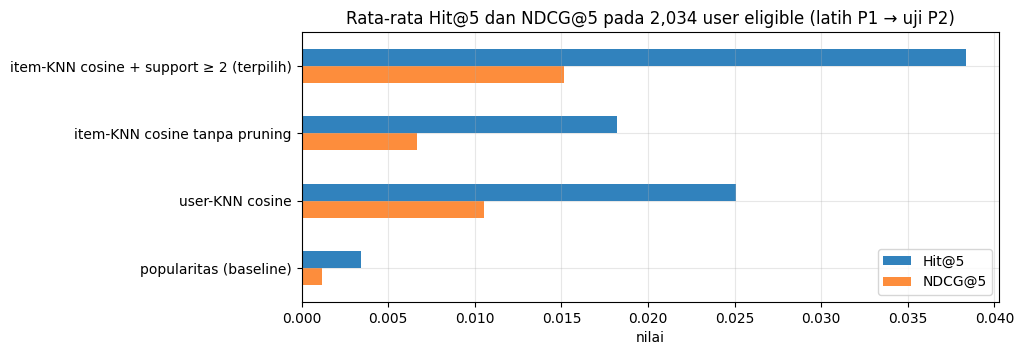

In [50]:
ax = validation.plot.barh(figsize=(9, 3.5), color=["#3182bd", "#fd8d3c"])
ax.invert_yaxis()
ax.set(title=f"Rata-rata Hit@5 dan NDCG@5 pada {len(pool):,} user eligible (latih P1 → uji P2)", xlabel="nilai")
plt.show()

## 3. Kesimpulan dan ringkasan jawaban

| Soal | Jawaban singkat |
|---|---|
| 1.2 Checkpoint 1 | Database `neo4j` (argumen `database_="neo4j"`; juga database default). |
| 1.2 Checkpoint 2 | `database_=` / `driver.session(database=...)`, klausa `USE`, `:use` di Browser, perintah administrasi di `system` (`SHOW/CREATE/ALTER/STOP/START/DROP DATABASE`, `CREATE ALIAS`), dan composite database. |
| 1.2 Checkpoint 3 | *Labeled property graph* berarah, tak berbobot, homogen, dan sederhana; berbentuk star graph S₃ (pohon kedalaman 1) berpusat di Arthur. |
| 2.1.1 | P1 (training) 7 Jun – 18 Jul 2015 dan P2 (testing) 19 Jul – 1 Agu 2015 (UTC), berurutan 6 + 2 minggu. |
| 2.1.2 | 460 duplikat dibuang; 1.193.338 event tersimpan di `data/events_filtered.csv` dengan kolom `fold`. |
| 2.1.3 | 621.168 `Visitor` + 163.295 `Item`; relasi `VIEWED` 1.153.867, `ADDED_TO_CART` 29.615, `BOUGHT` 9.856. |
| 2.1.4 | VSM user 455.767 × 142.244, density 1,05×10⁻⁵, 81% vektor hanya punya 1 elemen. |
| 2.1.5 | VSM item 142.244 × 455.767, rata-rata 4,78 elemen per vektor, 44,5% vektor hanya punya 1 elemen. |
| 2.1.6 | Proyeksi item–item lebih efisien (node 3,2× lebih sedikit, edge −24%, lebih cepat dan hemat memori) dan lebih efektif (vektor lebih padat; Hit@5 item-KNN 0,0383 vs user-KNN 0,0251). |
| 2.1.7 | Cosine + support ≥ 2, k = 5 → 77.316 relasi `SIMILAR`. Top-5 item 5411: 33030, 33956, 358234, 37807, 459936 (hasil Cypher = Python). |
| 2.1.8 | Sebelum: item hanya terhubung lewat visitor, 0 relasi `SIMILAR`. Sesudah: relasi langsung `(:Item)-[:SIMILAR {score}]->(:Item)`. |
| 2.2.1 | Visitor 1174645 (seed 2026). Item iklan: 294965, 194958, 244571. |
| 2.2.2 | Hit@5 = 0 dan NDCG@5 = 0 untuk user tersebut. Rata-rata seluruh user eligible: Hit@5 0,0383, NDCG@5 0,0151. |

**Keterbatasan dan saran.** Riwayat user sangat pendek (median satu item), dan setelah pruning hanya 16,6% item yang punya tetangga, sehingga banyak rekomendasi bergantung pada sedikit item. Perbaikan yang bisa dicoba: bobot TF-IDF untuk meredam visitor super-aktif, fitur konten (`item_properties`, `category_tree`) untuk item tanpa tetangga, atau periode P1 yang lebih panjang.

In [51]:
driver.close()